In [1]:
# Cell 1 — Imports
import numpy as np
import pandas as pd
import xarray as xr
import sys
import matplotlib.pyplot as plt
from pathlib import Path
import glob
sys.path.append(str(Path("../src").resolve()))
from radar_lwc.preprocessing.chirps import combine_chirps
from radar_lwc.preprocessing.get_reflectivity import get_reflectivity
from radar_lwc.preprocessing.clean import drop_duplicate_times
from radar_lwc.preprocessing.align import align_to_reference_time

## WHICH DAY /DATASET

In [2]:
KA_FILE    = "../data/raw/pallas/20261001_pallasjarvi_rpg-fmcw-35_delft.nc"
W_FILE     = "../data/raw/pallas/20261001_pallasjarvi_rpg-fmcw-94_granada.nc"

RANGE_MATCHING_METHOD = "gaussian"            # run 1. In the copied folder for run 2: "gaussian"
Processed_Dataset = f"20261001_pallas_{RANGE_MATCHING_METHOD}"   # separate output folder per method
CATEGORIZE_FILE = "../data/raw/pallas/20261001_pallasjarvi_categorize.nc"   # if you use option A in cell 25
MWR_FILE        = "../data/raw/pallas/20261001_pallasjarvi_hatpro-multi_T_h.nc"   # if you use option B in cell 25

Load Both Radars

In [3]:
 # Cell 2 — Load both
# same quantity, same shape -> your old RPG name (CloudnetPy rpg_reader.py keymap, read backwards)
TO_OLD_NAMES = {"lwp": "LWP", "air_pressure": "SurfPres", "radar_frequency": "Freq",
                "integration_time": "SeqIntTime", "number_of_averaged_chirps": "AvgNum",
                "number_of_spectral_samples": "DoppLen"}

def load_cloudnet(path):
    ds = xr.open_dataset(path)
    ds = ds.rename({"time": "Time"})
    ds = ds.assign_coords(Time=ds.Time.values.astype("datetime64[ns]"))
    ds = drop_duplicate_times(ds)
    ds = ds.rename({k: v for k, v in TO_OLD_NAMES.items() if k in ds})
    # back to the units your pipeline expects (CloudnetPy rpg.py convert_units, read backwards)
    if "LWP" in ds:
        ds["LWP"] = ds["LWP"] * 1000.0;        ds["LWP"].attrs["units"] = "g m-2"   # kg m-2 -> g m-2
    if "SurfPres" in ds:
        ds["SurfPres"] = ds["SurfPres"] / 100.0; ds["SurfPres"].attrs["units"] = "hPa"   # Pa -> hPa
    return ds

ds_w  = load_cloudnet(W_FILE)
ds_ka = load_cloudnet(KA_FILE)
print(ds_w); print(ds_ka)

<xarray.Dataset> Size: 944MB
Dimensions:                  (Time: 30288, chirp_sequence: 4, range: 860)
Coordinates:
  * Time                     (Time) datetime64[ns] 242kB 2026-10-01T00:00:00....
  * range                    (range) float32 3kB 216.0 252.0 ... 1.2e+04
Dimensions without coordinates: chirp_sequence
Data variables: (12/51)
    file_code                (Time) int32 121kB ...
    program_number           (Time) int32 121kB ...
    model_number             int32 4B ...
    Freq                     float32 4B ...
    antenna_separation       float32 4B ...
    antenna_diameter         float32 4B ...
    ...                       ...
    ldr                      (Time, range) float32 104MB ...
    rho_cx                   (Time, range) float32 104MB ...
    phi_cx                   (Time, range) float32 104MB ...
    altitude                 (Time) float32 121kB ...
    zenith_angle             (Time) float32 121kB ...
    height                   (range) float32 3kB ...
Att

In [4]:
def keep_native_program(ds):
    """Keep only profiles measured with the chirp program whose gates ARE the file's grid
    (Cloudnet interpolated all other programs onto that grid)."""
    spacing1 = float(np.median(np.diff(ds["range"].values[:10])))   # gate spacing in chirp 1
    rr1 = ds["range_resolution"].isel(chirp_sequence=0)
    keep = (np.abs(rr1 - spacing1) < 0.1).values
    print(f"kept {keep.sum()} of {keep.size} profiles")
    return ds.isel(Time=keep)

ds_ka = keep_native_program(ds_ka)
ds_w  = keep_native_program(ds_w)

kept 30216 of 30216 profiles
kept 30288 of 30288 profiles


In [5]:
with ds_ka as d:
    for v in ["SeqIntTime", "AvgNum", "DoppLen"]:
        print(f"{v:12s} {np.asarray(d[v].values).ravel()}")

SeqIntTime   [0.9157869  0.73262954 0.36631477 ... 0.9157869  0.73262954 0.36631477]
AvgNum       [8192 8192 4096 ... 8192 8192 4096]
DoppLen      [512 512 256 ... 512 512 256]


In [6]:

c   = 299792458.0
lam = c / (float(ds_ka["Freq"].values.flat[0]) * 1e9)

max_vel = ds_ka["nyquist_velocity"].values[0, ds_ka["chirp_start_indices"].values[0].astype(int)]
avg_num = ds_ka["AvgNum"].values[0, :].astype(float)
seq_int = ds_ka["SeqIntTime"].values[0, :]

T_chirp = seq_int / avg_num
print("lambda [mm]      :", lam * 1000)
print("chirp spacing [us]:", T_chirp * 1e6)
print("PRF from MaxVel  :", 4.0 * max_vel / lam)
print("AvgNum  :", avg_num )
print("v_Nyq implied    :", lam / (4.0 * T_chirp))

lambda [mm]      : 8.5654988
chirp spacing [us]: [111.79039575  89.4323166   89.4323166 ]
PRF from MaxVel  : [12260.061   9122.932   6123.1245]
AvgNum  : [8192. 8192. 4096.]
v_Nyq implied    : [19.1552654  23.94408175 23.94408175]


In [7]:

c   = 299792458.0
lam = c / (float(ds_w["Freq"].values.flat[0]) * 1e9)

max_vel = ds_w["nyquist_velocity"].values[0, ds_w["chirp_start_indices"].values[0].astype(int)]
avg_num = ds_w["AvgNum"].values[0, :].astype(float)
seq_int = ds_w["SeqIntTime"].values[0, :]

T_chirp = seq_int / avg_num
print("lambda [mm]      :", lam * 1000)
print("chirp spacing [us]:", T_chirp * 1e6)
print("PRF from MaxVel  :", 4.0 * max_vel / lam)
print("AvgNum  :", avg_num)
print("v_Nyq implied    :", lam / (4.0 * T_chirp))

lambda [mm]      : 3.189292081139043
chirp spacing [us]: [122.96943281  89.43231884 178.86462932 357.72925581]
PRF from MaxVel  : [12889.848   8601.366   4285.4985  2284.767 ]
AvgNum  : [6656. 6656. 3840. 1408.]
v_Nyq implied    : [6.48391232 8.91537903 4.45768973 2.22884488]


In [8]:
import glob
import numpy as np
import xarray as xr
from pathlib import Path


def check_range_sampling(ds, label=""):
    """
    Compare RPG's reported range resolution with the actual gate spacing,
    per chirp. Reads metadata from the first file, then confirms every other
    file in the folder uses the same chirp table.
    """
    rr = ds["range_resolution"].values[0]
    starts = ds["chirp_start_indices"].values[0].astype(int)
    ends = list(starts[1:]) + [ds.sizes["range"]]
    print(f"--- {label}")
    for c, (i0, i1) in enumerate(zip(starts, ends)):
        g = ds["range"].values[i0:i1]
        spacing = float(np.median(np.diff(g)))
        factor = float(rr[c]) / spacing
        status = "independent" if factor <= 1.01 else "CORRELATED"   # 1.01: float rounding
        print(f"  chirp {c+1}: gates {g[0]:6.0f}-{g[-1]:6.0f} m | {g.size:3d} gates | spacing {spacing:5.1f} m | "
              f"RangeRes {float(rr[c]):5.1f} m | oversampling x{factor:.2f}  -> {status}")

check_range_sampling(ds_ka, "Ka-band")
check_range_sampling(ds_w,  "W-band")

--- Ka-band
  chirp 1: gates    104-  1193 m |  74 gates | spacing  14.9 m | RangeRes  14.9 m | oversampling x1.00  -> independent
  chirp 2: gates   1202-  2997 m | 134 gates | spacing  13.5 m | RangeRes  13.5 m | oversampling x1.00  -> independent
  chirp 3: gates   3032- 10971 m | 234 gates | spacing  34.1 m | RangeRes  34.1 m | oversampling x1.00  -> independent
--- W-band
  chirp 1: gates    216-  1476 m |  36 gates | spacing  36.0 m | RangeRes  36.0 m | oversampling x1.00  -> independent
  chirp 2: gates   1482-  3986 m | 197 gates | spacing  12.8 m | RangeRes  12.8 m | oversampling x1.00  -> independent
  chirp 3: gates   3999-  8152 m | 326 gates | spacing  12.8 m | RangeRes  12.8 m | oversampling x1.00  -> independent
  chirp 4: gates   8165- 11998 m | 301 gates | spacing  12.8 m | RangeRes  12.8 m | oversampling x1.00  -> independent


In [9]:
rr = pd.DataFrame(ds_ka["range_resolution"].values).round(1)
rr["Time"] = ds_ka.Time.values
print(rr.groupby(list(rr.columns[:-1]), dropna=False)["Time"].agg(["min", "max", "count"]))

                                              min  \
0    1    2                                         
14.9 13.5 34.099998 2026-10-01 00:43:14.052958488   

                                              max  count  
0    1    2                                               
14.9 13.5 34.099998 2026-10-01 23:55:25.760650634  30216  


## Radar seperation and beam mismatch

In [10]:
import numpy as np
import glob

def haversine_m(lat1, lon1, lat2, lon2):
    R = 6_371_000.0
    p1, p2 = np.radians([lat1, lat2])
    a = (np.sin((p2-p1)/2)**2
         + np.cos(p1)*np.cos(p2)*np.sin(np.radians(lon2-lon1)/2)**2)
    return 2*R*np.arcsin(np.sqrt(a))


def beam_overlap(d, hpbw_a, hpbw_b, heights):
    """Fractional area overlap of two circular footprints separated by d."""
    h = np.asarray(heights, float)
    ra = h * np.tan(np.radians(hpbw_a)/2)
    rb = h * np.tan(np.radians(hpbw_b)/2)
    frac = np.zeros_like(h)
    for i, (R1, R2) in enumerate(zip(ra, rb)):
        if d >= R1 + R2:
            frac[i] = 0.0
        elif d <= abs(R1 - R2):
            frac[i] = 1.0
        else:
            a1 = np.arccos((d**2 + R1**2 - R2**2)/(2*d*R1))
            a2 = np.arccos((d**2 + R2**2 - R1**2)/(2*d*R2))
            area = (R1**2*(a1 - np.sin(2*a1)/2) + R2**2*(a2 - np.sin(2*a2)/2))
            frac[i] = area / (np.pi * min(R1, R2)**2)
    return 2*ra, 2*rb, frac



lat_ka, lon_ka = float(ds_ka["latitude"].median()), float(ds_ka["longitude"].median())
lat_w,  lon_w  = float(ds_w["latitude"].median()),  float(ds_w["longitude"].median())
hpbw_ka, hpbw_w = float(ds_ka["half_power_beam_width"]), float(ds_w["half_power_beam_width"])

sep = haversine_m(lat_ka, lon_ka, lat_w, lon_w)
print(f"separation      : {sep:.1f} m")
print(f"HPBW Ka / W     : {hpbw_ka:.3f} / {hpbw_w:.3f} deg")

hs = np.array([500., 750., 1000., 1400., 2000.])
Dka, Dw, frac = beam_overlap(sep, hpbw_ka, hpbw_w, hs)
for h, a, b, f in zip(hs, Dka, Dw, frac):
    print(f"  h={h:5.0f} m: beams {a:5.1f} / {b:5.1f} m | "
          f"separation {sep/(0.5*(a+b)):5.2f} beamwidths | overlap {f:.2f}")

separation      : 13.8 m
HPBW Ka / W     : 0.840 / 0.560 deg
  h=  500 m: beams   7.3 /   4.9 m | separation  2.26 beamwidths | overlap 0.00
  h=  750 m: beams  11.0 /   7.3 m | separation  1.51 beamwidths | overlap 0.00
  h= 1000 m: beams  14.7 /   9.8 m | separation  1.13 beamwidths | overlap 0.00
  h= 1400 m: beams  20.5 /  13.7 m | separation  0.81 beamwidths | overlap 0.15
  h= 2000 m: beams  29.3 /  19.5 m | separation  0.57 beamwidths | overlap 0.48


In [11]:
print(f"Ka: {lat_ka:.7f}, {lon_ka:.7f}")
print(f"W : {lat_w:.7f}, {lon_w:.7f}")

Ka: 68.0226974, 24.1594887
W : 68.0225754, 24.1594257


In [12]:
print("W DualPol:", int(ds_w["dual_polarization"]), "| Ka DualPol:", int(ds_ka["dual_polarization"]))

W DualPol: 1 | Ka DualPol: 2


In [13]:
print(ds_ka.variables)

Frozen({'file_code': <xarray.Variable (Time: 30216)> Size: 121kB
[30216 values with dtype=int32]
Attributes:
    units:      1
    long_name:  File code
    comment:    Indicates the RPG software version., 'program_number': <xarray.Variable (Time: 30216)> Size: 121kB
[30216 values with dtype=int32]
Attributes:
    units:      1
    long_name:  Program number, 'model_number': <xarray.Variable ()> Size: 4B
[1 values with dtype=int32]
Attributes:
    units:       1
    long_name:   Model number
    definition:  \nValue 0: Single polarisation radar.\nValue 1: Dual polaris..., 'Freq': <xarray.Variable ()> Size: 4B
array(35., dtype=float32)
Attributes:
    units:      GHz
    long_name:  Radar transmit frequency, 'antenna_separation': <xarray.Variable ()> Size: 4B
[1 values with dtype=float32]
Attributes:
    units:      m
    long_name:  Antenna separation, 'antenna_diameter': <xarray.Variable ()> Size: 4B
[1 values with dtype=float32]
Attributes:
    units:      m
    long_name:  Antenna d

Reflectivities

In [14]:
# Cell 3 — Reflectivities 13
ze_w  = ds_w["Zh"]      # dBZ, chirps already merged
ze_ka = ds_ka["Zh"]

Ranges and Time Coverage

In [15]:
# Cell 4 — Inspect ranges & time coverage  ← KEEP, condensed
print(f"W : {ze_w['range'].values[0]:.1f} → {ze_w['range'].values[-1]:.1f} m  ({ze_w.sizes['range']} gates)")
print(f"Ka: {ze_ka['range'].values[0]:.1f} → {ze_ka['range'].values[-1]:.1f} m  ({ze_ka.sizes['range']} gates)")
identical = (ze_w.sizes["range"] == ze_ka.sizes["range"]) and np.allclose(ze_w["range"].values, ze_ka["range"].values)
print(f"Ranges identical: {identical}")

# Time coverage
print(f"\nW  : {ze_w.Time.values[0]}  →  {ze_w.Time.values[-1]}  ({ze_w.sizes['Time']} samples)")
print(f"Ka : {ze_ka.Time.values[0]}  →  {ze_ka.Time.values[-1]}  ({ze_ka.sizes['Time']} samples)")

# Temporal resolution
dt_ka = (ze_ka.Time.diff("Time") / np.timedelta64(1,"s")).median().values
dt_w  = (ze_w.Time.diff("Time")  / np.timedelta64(1,"s")).median().values
print(f"\nMedian Δt  W={dt_w:.1f}s   Ka={dt_ka:.1f}s")


W : 216.0 → 11997.6 m  (860 gates)
Ka: 104.3 → 10970.7 m  (442 gates)
Ranges identical: False

W  : 2026-10-01T00:00:00.646000035  →  2026-10-01T23:59:58.585510253  (30288 samples)
Ka : 2026-10-01T00:43:14.052958488  →  2026-10-01T23:55:25.760650634  (30216 samples)

Median Δt  W=2.8s   Ka=2.2s


==================================================================================================================================================

ALIGN TIME

==================================================================================================================================================

In [16]:
# Cell 5 — Common time grid  --> If it is more then a little part that is missing for the time steps

# ze_w_c = align_to_reference_time(
    #da_ref=ze_ka,
    #da_target=ze_w,
    #method="nearest"
#)

#ze_ka_c = ze_ka

In [17]:
# Cell 6 — Range alignment (only if not identical)
#if not identical:
 # ze_ka_c = ze_ka_c.interp(range=ze_w_c["range"])

In [18]:
print(len(ze_w.Time))
print(len(ze_ka.Time))

30288
30216


In [19]:
# =====================================================================================
# CELL 18 - MATCH THE TWO RADARS IN TIME              (identical in both runs)
# Ka is the reference clock: every Ka profile gets the W profile that is closest in time.
# Replaces your current step-18 cell completely.
# =====================================================================================

# Typical time between two consecutive profiles of each radar.
# .diff() = difference between neighbouring time stamps; the median ignores the few long gaps.
time_step_w  = pd.Series(ds_w.Time.values).diff().median()
time_step_ka = pd.Series(ds_ka.Time.values).diff().median()

# Largest time difference that still counts as "the same moment": half the slower radar's time step.
# (My choice, not from a paper: within half a step a Ka profile can only be paired with the W profile
#  whose own sampling interval it falls into - never with the one before or after.)
time_tolerance = max(time_step_w, time_step_ka) / 2

# For every Ka time stamp: position of the nearest W time stamp, or -1 if no W profile lies within
# the tolerance (W gap, radar off). pandas does this search: DatetimeIndex.get_indexer(method="nearest").
nearest_w_index = pd.DatetimeIndex(ds_w.Time.values).get_indexer(
    ds_ka.Time.values, method="nearest", tolerance=time_tolerance)

has_w_partner = nearest_w_index >= 0                  # True for Ka profiles that found a W partner
common_times  = ds_ka.Time.values[has_w_partner]      # the time axis both radars share from now on


def w_at_common_times(w_variable):
    """Any W variable with a Time axis -> for every common time the nearest W profile,
    relabelled with the Ka time stamp, so W and Ka end up with identical time labels."""
    nearest_w = w_variable.sel(Time=common_times, method="nearest", tolerance=time_tolerance)
    return nearest_w.assign_coords(Time=common_times)


# Quality check of the pairing: the real time difference between paired profiles, in seconds.
time_offset_s = (ds_w.Time.values[nearest_w_index[has_w_partner]] - common_times) / np.timedelta64(1, "s")

print(f"W : {ds_w.sizes['Time']} profiles, time step {time_step_w.total_seconds():.1f} s")
print(f"Ka: {ds_ka.sizes['Time']} profiles, time step {time_step_ka.total_seconds():.1f} s")
print(f"common times: {common_times.size} (tolerance {time_tolerance.total_seconds():.1f} s) | "
      f"time offset median {np.median(np.abs(time_offset_s)):.2f} s, max {np.abs(time_offset_s).max():.2f} s")

W : 30288 profiles, time step 2.8 s
Ka: 30216 profiles, time step 2.2 s
common times: 29682 (tolerance 1.4 s) | time offset median 0.70 s, max 1.40 s


In [20]:
# =====================================================================================
# CELL 20a - RANGE-MATCHING TOOLS                    (identical in both runs; new cell after cell 18)
# Both methods do the same thing: every value on the common grid is a WEIGHTED AVERAGE of one
# radar's own gates. They only differ in the weights:
#   interpolation -> the two neighbouring gates, weighted by distance
#   gaussian      -> a bell curve over several gates (Williams & Vivekanandan 2007)
# The weights live in a "weight table": one row per common gate, one column per radar gate.
# =====================================================================================

def linear_interpolation_weights(source_range, target_range):
    """Weight table for linear interpolation from a radar's own gates (source_range) to the
    common gates (target_range). Each row has at most two non-zero weights; they add up to 1."""
    n_source_gates = source_range.size
    # Index of the first radar gate at or above each target height (binary search, numpy.searchsorted).
    upper_gate = np.searchsorted(source_range, target_range, side="left")
    upper_gate = np.clip(upper_gate, 1, n_source_gates - 1)       # always keep a valid pair below/above
    lower_gate = upper_gate - 1
    # Where the target lies between the two gates: 0 = exactly on the lower gate, 1 = on the upper gate.
    fraction = (target_range - source_range[lower_gate]) / (source_range[upper_gate] - source_range[lower_gate])
    weight_table = np.zeros((target_range.size, n_source_gates))
    # Only targets inside the radar's own height coverage get weights (no extrapolation).
    inside = (target_range >= source_range[0]) & (target_range <= source_range[-1])
    rows = np.flatnonzero(inside)
    weight_table[rows, lower_gate[inside]] += 1.0 - fraction[inside]   # the closer gate gets the larger weight
    weight_table[rows, upper_gate[inside]] += fraction[inside]
    return weight_table      # a target exactly on a radar gate gets weight 1 there -> value unchanged


def apply_range_weights(field_linear, weight_table, target_range, min_valid_weight_fraction=0.5):
    """Weighted average along range, for all profiles at once:
    result[t, i] = sum_j weight[i, j] * field[t, j] / sum_j weight[i, j]   (only gates j that have data)."""
    values = field_linear.transpose("Time", "range").values      # numpy array (time, radar gates)
    has_data = np.isfinite(values)                                # False where Cloudnet masked the gate (no echo)
    # Matrix product = for every profile and every common gate: the sum of weight x value.
    weighted_sum = np.where(has_data, values, 0.0) @ weight_table.T
    valid_weight = has_data.astype(float) @ weight_table.T        # sum of the weights of the gates WITH data
    total_weight = weight_table.sum(axis=1)                       # sum of all weights in a row
    with np.errstate(invalid="ignore", divide="ignore"):
        result = weighted_sum / valid_weight                      # weighted mean over the gates with data
    # If less than half of a row's weight has data (cloud edge), don't invent a value -> NaN.
    # (My choice. Same rule in both methods, so cloud edges are treated identically in the comparison.)
    result[valid_weight < min_valid_weight_fraction * total_weight] = np.nan
    return xr.DataArray(result, dims=("Time", "range"),
                        coords={"Time": field_linear["Time"].values, "range": target_range})


def match_reflectivity_and_velocity(reflectivity_dbz, doppler_velocity, weight_table, target_range):
    """Put one radar's reflectivity and Doppler velocity onto the common grid with a weight table."""
    # Reflectivity adds up in linear units (mm^6 m^-3 = sum of D^6 per volume), not in dB. Averaging
    # dB values gives a biased (too low) value, so: dBZ -> linear -> weighted average -> dBZ.
    z_linear = 10.0 ** (reflectivity_dbz / 10.0)
    reflectivity_common_dbz = 10.0 * np.log10(apply_range_weights(z_linear, weight_table, target_range))
    # Mean Doppler velocity = reflectivity-weighted mean velocity of a volume (first moment of the Doppler
    # spectrum). Combining gates = adding their spectra, so the velocities must be weighted with Z as well:
    # v_common = average(Z * v) / average(Z), using only gates that have a velocity.
    z_where_velocity = z_linear.where(doppler_velocity.notnull())
    velocity_common = (apply_range_weights(z_where_velocity * doppler_velocity, weight_table, target_range)
                       / apply_range_weights(z_where_velocity, weight_table, target_range))
    return reflectivity_common_dbz, velocity_common


def effective_number_of_gates(weight_table):
    """(sum w)^2 / sum(w^2) = how many independent radar gates one common gate is worth
    (Kish's effective sample size). 1 = a single gate. If the radar's gates are independent,
    the noise of the common gate is reduced by sqrt(this number)."""
    with np.errstate(invalid="ignore", divide="ignore"):
        return weight_table.sum(axis=1) ** 2 / (weight_table ** 2).sum(axis=1)

In [21]:
# =====================================================================================
# CELL 20b - RANGE MATCHING WITH A GAUSSIAN KERNEL     (run 2, in the copied folder)
# Williams & Vivekanandan (2007), JTECH 24, pp. 1329-1332, Fig. 11 + conclusions: resample the finer
# radar to the coarser radar's gates by convolving its LINEAR reflectivity with a Gaussian kernel.
# Common grid = at every height the gates of whichever radar is coarser there.
# Replaces the interpolation version of cell 20b; cells 18 and 20a stay as they are.
# =====================================================================================
assert RANGE_MATCHING_METHOD == "gaussian", "this is the gaussian cell - check step 2"

# A bell curve's full width at half maximum = 2*sqrt(2*ln 2)*sigma = 2.3548*sigma.
# ASSUMPTION (state it in Ch. 5): RangeRes = full width at half maximum of a Gaussian range-weighting
# function. The real RPG weighting function is shaped by its FFT window, so this is an approximation.
FWHM_TO_SIGMA = 1.0 / 2.3548


def gate_resolution(ds):
    """Range resolution [m] of every gate. Cloudnet stores RangeRes once per chirp:
    range_resolution <- RPG 'dR', chirp_start_indices <- RPG 'RngOffs' (CloudnetPy rpg_reader.py)."""
    chirp_first_gate = ds["chirp_start_indices"].values[0].astype(int)    # first gate of each chirp (profile 0)
    chirp_resolution = ds["range_resolution"].values[0].astype(float)     # RangeRes of each chirp (profile 0)
    resolution = np.empty(ds.sizes["range"])
    for chirp_number, first_gate in enumerate(chirp_first_gate):
        resolution[first_gate:] = chirp_resolution[chirp_number]          # from this chirp up; next chirp overwrites
    return resolution


def value_at_nearest_gate(heights, gate_heights, gate_values):
    """For each height: the value of the closest gate (used to compare the two radars at one height)."""
    nearest_gate = np.abs(gate_heights[None, :] - np.asarray(heights)[:, None]).argmin(axis=1)
    return gate_values[nearest_gate]


def gaussian_kernel_weights(source_range, source_resolution, target_range, target_resolution):
    """Weight table that blurs one radar from its own resolution to the target (coarser) resolution."""
    nearest_source_gate = np.abs(source_range[None, :] - target_range[:, None]).argmin(axis=1)
    # Blurring twice with bell curves adds their variances: sigma_target^2 = sigma_source^2 + sigma_kernel^2.
    # So the kernel adds only the missing blur; it is 0 where this radar already is the coarser one.
    kernel_sigma = FWHM_TO_SIGMA * np.sqrt(np.clip(
        target_resolution ** 2 - source_resolution[nearest_source_gate] ** 2, 0.0, None))
    distance = source_range[None, :] - target_range[:, None]          # every radar gate vs every common gate [m]
    with np.errstate(divide="ignore", invalid="ignore"):
        weight_table = np.exp(-0.5 * (distance / kernel_sigma[:, None]) ** 2)   # bell centred on each common gate
    # A bell narrower than half this radar's gate spacing cannot be represented on its gates: it would just
    # pick the nearest gate, up to half a gate away from the target. That happens where the resolutions
    # already match (Ka chirp 2: 13.5 m vs W 12.8 m) or where this radar is the coarser one (kernel = 0).
    # There the only job left is shifting to the common gate positions -> linear interpolation weights in
    # those rows (on the radar's own gate that is weight 1 = value unchanged). (My choice; tested.)
    gate_spacing = np.gradient(source_range)
    too_narrow = kernel_sigma < 0.5 * gate_spacing[nearest_source_gate]
    weight_table[too_narrow] = linear_interpolation_weights(source_range, target_range[too_narrow])
    return weight_table, kernel_sigma


range_ka, resolution_ka = ze_ka["range"].values.astype(float), gate_resolution(ds_ka)
range_w,  resolution_w  = ze_w["range"].values.astype(float),  gate_resolution(ds_w)

# Common grid: heights both radars cover; at each height the gates of whichever radar is coarser.
overlap_bottom = max(range_ka[0], range_w[0])
overlap_top    = min(range_ka[-1], range_w[-1])
w_gate_inside  = (range_w  >= overlap_bottom) & (range_w  <= overlap_top)
ka_gate_inside = (range_ka >= overlap_bottom) & (range_ka <= overlap_top)
w_is_coarser_here  = resolution_w  >= value_at_nearest_gate(range_w,  range_ka, resolution_ka)
ka_is_coarser_here = resolution_ka >  value_at_nearest_gate(range_ka, range_w,  resolution_w)
common_range = np.unique(np.concatenate([range_w[w_gate_inside & w_is_coarser_here],       # merged + sorted
                                         range_ka[ka_gate_inside & ka_is_coarser_here]]))
# The resolution every common gate should end up with = the coarser of the two radars at that height.
common_resolution = np.maximum(value_at_nearest_gate(common_range, range_ka, resolution_ka),
                               value_at_nearest_gate(common_range, range_w,  resolution_w))

weights_ka, kernel_sigma_ka = gaussian_kernel_weights(range_ka, resolution_ka, common_range, common_resolution)
weights_w,  kernel_sigma_w  = gaussian_kernel_weights(range_w,  resolution_w,  common_range, common_resolution)

ze_ka_c, MeanVel_Ka_c = match_reflectivity_and_velocity(
    ze_ka.sel(Time=common_times), ds_ka["v"].sel(Time=common_times), weights_ka, common_range)
ze_w_c, MeanVel_W_c = match_reflectivity_and_velocity(
    w_at_common_times(ze_w), w_at_common_times(ds_w["v"]), weights_w, common_range)

# What happened at a few heights: which radar was blurred, by how much, how many of its gates went in.
n_eff_ka, n_eff_w = effective_number_of_gates(weights_ka), effective_number_of_gates(weights_w)
for height in (500, 1000, 2000, 5000):
    i = np.abs(common_range - height).argmin()
    print(f"{common_range[i]:7.1f} m | target resolution {common_resolution[i]:4.1f} m | "
          f"Ka kernel {kernel_sigma_ka[i]:4.1f} m = {n_eff_ka[i]:.2f} gates | "
          f"W kernel {kernel_sigma_w[i]:4.1f} m = {n_eff_w[i]:.2f} gates")
print(f"common grid: {common_range.size} gates, {common_range[0]:.0f}-{common_range[-1]:.0f} m | "
      f"after matching: Ka {ze_ka_c.shape}, W {ze_w_c.shape}")

  504.0 m | target resolution 36.0 m | Ka kernel 13.9 m = 3.31 gates | W kernel  0.0 m = 1.00 gates
 1008.0 m | target resolution 36.0 m | Ka kernel 13.9 m = 3.31 gates | W kernel  0.0 m = 1.00 gates
 1998.0 m | target resolution 13.5 m | Ka kernel  0.0 m = 1.00 gates | W kernel  1.9 m = 1.89 gates
 5008.4 m | target resolution 34.1 m | Ka kernel  0.0 m = 1.00 gates | W kernel 13.4 m = 3.72 gates
common grid: 383 gates, 216-10971 m | after matching: Ka (29682, 383), W (29682, 383)


In [22]:
# Cell 7 — Verify
print(f"After alignment: W={ze_w_c.shape}, Ka={ze_ka_c.shape}")
assert ze_w_c.shape == ze_ka_c.shape, "Shapes still don't match!"
print("✅ Aligned on common (time, range) grid")

After alignment: W=(29682, 383), Ka=(29682, 383)
✅ Aligned on common (time, range) grid


==================================================================================================================================================

PLOT

==================================================================================================================================================

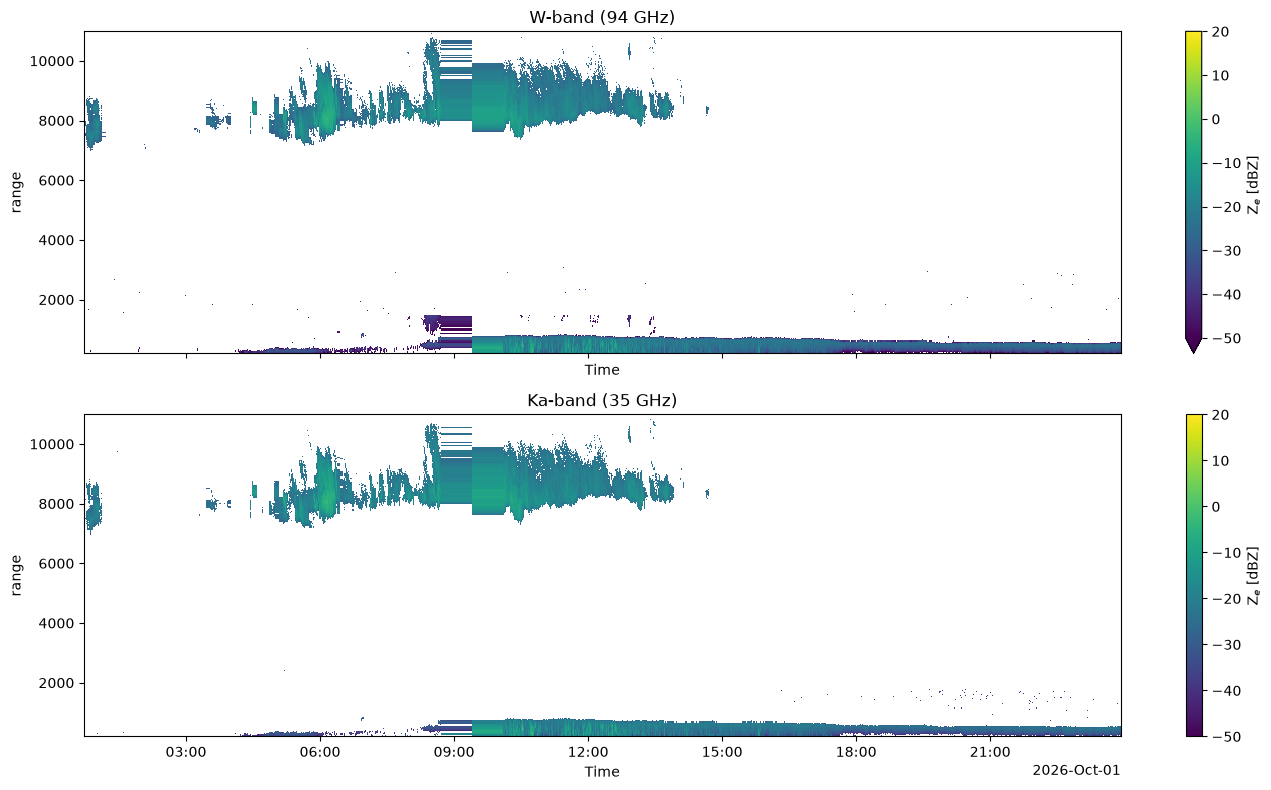

In [23]:
# Cell 8 — Side-by-side plot
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, sharey=True)
ze_w_c.plot(x="Time", y="range", ax=axes[0], cmap="viridis", vmin=-50, vmax=20, cbar_kwargs={"label": "Z$_e$ [dBZ]"})
axes[0].set_title("W-band (94 GHz)")
ze_ka_c.plot(x="Time", y="range", ax=axes[1], cmap="viridis", vmin=-50, vmax=20, cbar_kwargs={"label": "Z$_e$ [dBZ]"})
axes[1].set_title("Ka-band (35 GHz)")
plt.tight_layout()
plt.show()

(array([1.1510e+03, 3.4160e+03, 4.0290e+03, 4.5360e+03, 5.2060e+03,
        5.7970e+03, 6.1980e+03, 6.9400e+03, 7.5280e+03, 7.8450e+03,
        8.3800e+03, 9.1660e+03, 9.6690e+03, 1.0776e+04, 1.1133e+04,
        1.2475e+04, 1.3171e+04, 1.4515e+04, 1.5840e+04, 1.7095e+04,
        1.8643e+04, 2.0399e+04, 2.2606e+04, 2.5992e+04, 3.1555e+04,
        3.9156e+04, 4.7689e+04, 5.6580e+04, 6.3386e+04, 6.5124e+04,
        6.4870e+04, 6.8837e+04, 7.1243e+04, 6.1340e+04, 5.0268e+04,
        4.1682e+04, 3.5278e+04, 3.0267e+04, 2.6643e+04, 2.4065e+04,
        2.1073e+04, 1.7731e+04, 1.5267e+04, 1.3436e+04, 1.1926e+04,
        1.0371e+04, 9.1260e+03, 7.6920e+03, 6.0080e+03, 4.4400e+03,
        3.5800e+03, 3.1330e+03, 2.3900e+03, 1.5060e+03, 8.1600e+02,
        4.0800e+02, 1.9700e+02, 1.7300e+02, 9.6000e+01, 1.0000e+02,
        7.0000e+01, 2.7000e+01, 1.3000e+01, 1.2000e+01, 3.0000e+00,
        0.0000e+00, 1.0000e+00, 0.0000e+00, 0.0000e+00, 1.0000e+00,
        0.0000e+00, 1.0000e+00, 0.0000e+00, 0.00

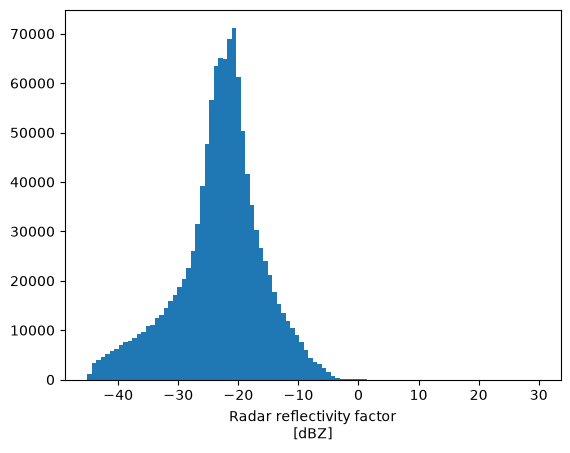

In [24]:
ze_ka.plot.hist(bins=100)

TEMPERATURE

==================================================================================================================================================

The T Profile Values are interpolated onto the Range grid. First we have to get the altitudes for the Temperature Profile in T_Alts, because Temperature Profile T_Prof only has Indices 1,2,3,.... Afterwards T_Prof uses T_Alts Altitudes and then the Values are interpolated onto the range grid

==================================================================================================================================================

In [25]:
mwr = xr.open_dataset(MWR_FILE)

In [26]:
mwr

<xarray.Dataset> Size: 224kB
Dimensions:                           (time: 143, height: 94)
Coordinates:
  * time                              (time) datetime64[ns] 1kB 2026-10-01T00...
  * height                            (height) float32 376B 275.0 ... 1.028e+04
Data variables: (12/13)
    latitude                          (time) float32 572B ...
    longitude                         (time) float32 572B ...
    altitude                          (time) float32 572B ...
    quality_flag                      (time) float64 1kB ...
    quality_flag_status               (time) float64 1kB ...
    elevation_angle                   (time) float32 572B ...
    ...                                ...
    temperature                       (time, height) float32 54kB ...
    temperature_quality_flag          (time) float64 1kB ...
    temperature_quality_flag_status   (time) float64 1kB ...
    relative_humidity                 (time, height) float32 54kB ...
    potential_temperature             (time, height) float32 54kB ...
    equivalent_potential_temperature  (time, height) float32 54kB ...
Attributes: (12/16)
    year:                         2026
    month:                        10
    day:                          01
    location:                     Pallasjärvi
    source:                       RPG-Radiometer Physics HATPRO\nVaisala CL31
    Conventions:                  CF-1.8
    ...                           ...
    history:                      2026-10-02 00:13:54 +00:00 - MWR multiple-p...
    source_file_uuids:            4918b416-4abb-487e-8c94-7fce623c26f8
    mwrpy_version:                1.7.2
    instrument_pid:               https://hdl.handle.net/21.12132/3.46797fd61...
    pid:                          https://hdl.handle.net/21.12132/1.27919fb75...
    cloudnet_processing_version:  2.65.10

In [27]:
# =====================================================================================
# CELL 25 - TEMPERATURE / HUMIDITY / PRESSURE PROFILES ONTO THE RADAR GRID
# Works for any source that gives values on (time x height above sea level).
# Replaces steps 24, 25 and 28 (TProf/AHProf no longer exist in the Cloudnet radar files).
# =====================================================================================

def profile_to_common_grid(profile_values, profile_times, profile_heights_asl, max_time_gap_minutes=60):
    """(source times x source heights) -> (common_times x common_range):
    first interpolate every source profile in height, then in time."""
    # Height of each common gate above mean sea level. Cloudnet 'altitude' = site altitude above mean sea
    # level (CloudnetPy metadata.py); the radar points vertically, so gate height = range + altitude
    # (Cloudnet computes its own 'height' variable the same way: cloudnet_instrument.py, add_height).
    common_heights_asl = common_range + float(ds_ka["altitude"].median())
    values  = np.asarray(profile_values, dtype=float)                                     # (source times, levels)
    heights = np.broadcast_to(np.asarray(profile_heights_asl, dtype=float), values.shape)   # 1-D heights -> every time
    on_radar_heights = np.full((values.shape[0], common_range.size), np.nan)
    for i in range(values.shape[0]):                                  # one source profile at a time
        usable = np.isfinite(values[i]) & np.isfinite(heights[i])     # skip missing levels
        if usable.sum() < 2:
            continue                                                  # empty profile -> stays NaN
        order = np.argsort(heights[i][usable])                        # np.interp needs increasing heights
        on_radar_heights[i] = np.interp(common_heights_asl,
                                        heights[i][usable][order], values[i][usable][order],
                                        right=np.nan)                 # above the profile top: no value
                                                                      # (below the lowest level: lowest value)
    profile = xr.DataArray(on_radar_heights, dims=("profile_time", "range"),
                           coords={"profile_time": np.asarray(profile_times).astype("datetime64[ns]"),
                                   "range": common_range})
    # NEW 1: drop source profiles without any value (MWR gap, rain/quality flag). Otherwise a single empty
    # profile makes every radar time between its two neighbours NaN; now the interpolation bridges it.
    profile = profile.dropna("profile_time", how="all")
    common_time_axis = xr.DataArray(common_times, dims="Time", coords={"Time": common_times})
    # Between two source profiles: linear interpolation in time (as before).
    linear = profile.interp(profile_time=common_time_axis).drop_vars("profile_time")
    # NEW 2: before the first / after the last source profile, linear interpolation has nothing on one side
    # and gives NaN -> use the nearest source profile there instead.
    nearest = profile.sel(profile_time=common_time_axis, method="nearest")
    time_to_nearest_profile = np.abs(nearest["profile_time"].values - common_times)
    on_common_grid = linear.fillna(nearest.drop_vars("profile_time"))
    # NEW 3: no source profile within max_time_gap_minutes -> no value, instead of stretching one profile
    # over hours. (My choice: 60 min; temperature changes slowly, but not over a whole afternoon.)
    too_far = xr.DataArray(time_to_nearest_profile > np.timedelta64(max_time_gap_minutes, "m"),
                           dims="Time", coords={"Time": common_times})
    return on_common_grid.where(~too_far)


# ---------- OPTION A: Cloudnet CATEGORIZE file (your supervisor's suggestion) ----------
# temperature [K], pressure [Pa], q [kg/kg] on (model_time, model_height); model_height is above mean
# sea level (CloudnetPy categorize.py). These are the weather MODEL's fields, copied from the model file -
# not measurements. Don't use 'Tw': that is wet-bulb temperature.
# categorize = xr.open_dataset(CATEGORIZE_FILE)
# model_grid = dict(profile_times=categorize["model_time"].values,
#                   profile_heights_asl=categorize["model_height"].values)
# T_on_range = profile_to_common_grid(categorize["temperature"].values, **model_grid).rename("T_cloud")   # K
# pressure_pa = profile_to_common_grid(categorize["pressure"].values, **model_grid)                       # Pa
# specific_humidity = profile_to_common_grid(categorize["q"].values, **model_grid)                        # kg/kg
# # Absolute humidity = q x air density; air density = p / (R_d * T_virtual), T_virtual = T * (1 + 0.608 q).
# AH_on_range = (1000.0 * specific_humidity * pressure_pa
#                / (287.05 * T_on_range * (1 + 0.608 * specific_humidity))).rename("AH_cloud")           # g m-3
# P_cloud = (pressure_pa / 100.0).rename("P_cloud")                                                       # hPa

# ---------- OPTION B: Cloudnet MWR product (mwr-single or mwr-multi) ----------
# temperature [K] and absolute_humidity [kg m-3] on (time, height); height is above mean sea level
# (mwrpy level2/lev2_meta_nc.py, which Cloudnet uses to make these products). No pressure profile ->
# keep your barometric P_cloud cell (step 32) with this option.
mwr = xr.open_dataset(MWR_FILE)

# ---------- 1) CHECK what the file contains: names, dimensions, units, value ranges ----------
for name in ("temperature", "relative_humidity", "height", "time"):
    if name not in mwr:
        print(f"{name:18s} NOT IN FILE -> look at print(mwr) for the right name")
        continue
    variable = mwr[name]
    if variable.dtype.kind in "fi":                                   # numbers: show min and max
        value_range = f"{float(variable.min()):.2f} to {float(variable.max()):.2f}"
    else:                                                             # time stamps: show first and last
        value_range = f"{variable.values[0]} to {variable.values[-1]}"
    print(f"{name:18s} dims {variable.dims} | units {variable.attrs.get('units')!r} | "
          f"{variable.attrs.get('long_name', '')!r} | {value_range}")

# ---------- 2) TEMPERATURE -> Kelvin ----------
temperature = mwr["temperature"].transpose("time", ...)              # make sure the order is (time, height)
if float(temperature.max()) < 100:          # no air temperature is below 100 K, so values below 100 must be degC
    print("temperature looks like degC -> converting to K")
    temperature = temperature + 273.15
temperature_k = temperature.values

# ---------- 3) RELATIVE HUMIDITY -> fraction 0..1 ----------
# Cloudnet/mwrpy stores it as a fraction (units "1"); other files use %. Values above 1.5 can only be %.
relative_humidity = mwr["relative_humidity"].transpose("time", ...)
if float(relative_humidity.max()) > 1.5:
    print("relative humidity looks like % -> converting to fraction")
    relative_humidity = relative_humidity / 100.0
relative_humidity_fraction = relative_humidity.values
assert relative_humidity_fraction.shape == temperature_k.shape, "T and RH are on different grids - tell me"

# ---------- 4) RELATIVE -> ABSOLUTE HUMIDITY, on the MWR's own grid ----------
# Saturation vapour pressure over liquid water, Magnus formula (Alduchov & Eskridge 1996), T in degC -> Pa.
temperature_c = temperature_k - 273.15
saturation_vapour_pressure_pa = 611.94 * np.exp(17.625 * temperature_c / (temperature_c + 243.04))
# Relative humidity = vapour pressure / saturation vapour pressure  ->  vapour pressure:
vapour_pressure_pa = relative_humidity_fraction * saturation_vapour_pressure_pa
# Ideal gas law for water vapour: absolute humidity = e / (R_v * T), R_v = 461.5 J kg-1 K-1 -> kg m-3, x1000 -> g m-3.
# (No pressure needed for this conversion.)
absolute_humidity_g_m3 = 1000.0 * vapour_pressure_pa / (461.5 * temperature_k)

# ---------- 5) ONTO THE RADAR GRID (function from the top of this cell) ----------
# profile_to_common_grid expects heights above MEAN SEA LEVEL. If the height check above says
# "above ground", use: mwr["height"].values + float(ds_ka["altitude"].median())
mwr_grid = dict(profile_times=mwr["time"].values, profile_heights_asl=mwr["height"].values)
T_on_range  = profile_to_common_grid(temperature_k, **mwr_grid).rename("T_cloud")              # K
AH_on_range = profile_to_common_grid(absolute_humidity_g_m3, **mwr_grid).rename("AH_cloud")    # g m-3

T_on_range.attrs["units"] = "K"
AH_on_range.attrs["units"] = "g m-3"
print(f"T : {float(T_on_range.min()):.1f} to {float(T_on_range.max()):.1f} K, shape {T_on_range.shape}")
print(f"AH: {float(AH_on_range.min()):.2f} to {float(AH_on_range.max()):.2f} g m-3")

temperature        dims ('time', 'height') | units 'K' | 'Temperature' | 224.90 to 283.71
relative_humidity  dims ('time', 'height') | units '1' | 'Relative humidity' | 0.01 to 1.32
height             dims ('height',) | units 'm' | 'Height above mean sea level' | 275.00 to 10275.00
time               dims ('time',) | units None | 'Time UTC' | 2026-10-01T00:10:29.000008106 to 2026-10-01T23:50:36.998748779
T : 225.1 to 283.7 K, shape (29682, 383)
AH: 0.02 to 7.26 g m-3


In [28]:
profile_without_T = T_on_range.sel(range=slice(0, 4000)).isnull().all("range").values
print("radar profiles without T:", int(profile_without_T.sum()),
      "| from", common_times[profile_without_T][:1], "to", common_times[profile_without_T][-1:])
print("radar:", common_times[0], "->", common_times[-1])
print("MWR  :", mwr.time.values[0], "->", mwr.time.values[-1],
      "| empty MWR profiles at:", mwr.time.values[np.isnan(temperature_k).all(axis=1)])

radar profiles without T: 0 | from [] to []
radar: 2026-10-01T00:43:14.052958488 -> 2026-10-01T23:55:23.535919189
MWR  : 2026-10-01T00:10:29.000008106 -> 2026-10-01T23:50:36.998748779 | empty MWR profiles at: []


In [29]:
print(T_on_range.shape)                                # should match ze_w_c.shape
print(f"{float(T_on_range.min()):.1f} → {float(T_on_range.max()):.1f} °K")
print("NaN in T below 4 km:", int(T_on_range.sel(range=slice(0, 4000)).isnull().sum()), "(should be 0)")
# Expect roughly: -60 → +20 °C  for Cabauw autumn

(29682, 383)
225.1 → 283.7 °K
NaN in T below 4 km: 0 (should be 0)


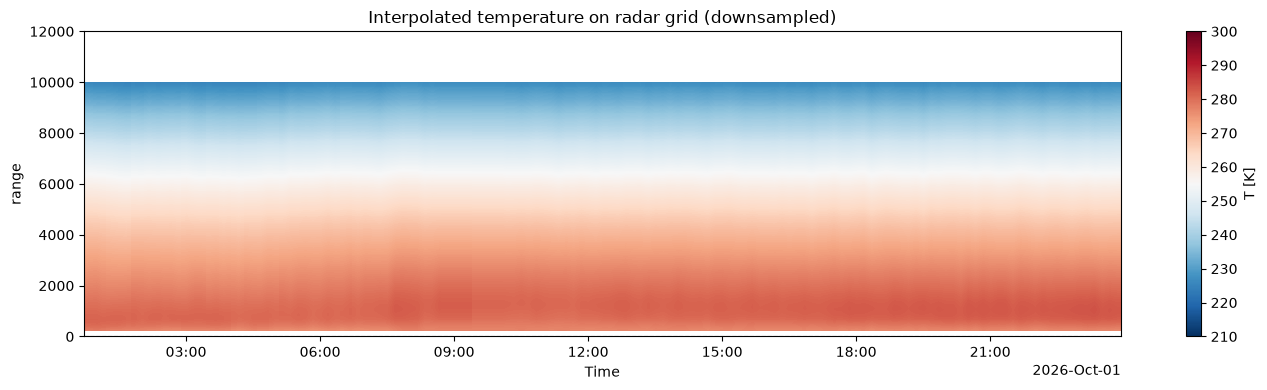

In [30]:

fig, ax = plt.subplots(1, 1, figsize=(14, 4))

T_on_range.isel(Time=slice(0, None, 5)).plot(
    x="Time",
    y="range",
    ax=ax,
    cmap="RdBu_r",
    vmin=210,
    vmax=300,
    cbar_kwargs={"label": "T [K]"},
)

ax.axhline(0, ls="--", c="k", lw=0.8, alpha=0.5)
ax.set_ylim(0, 12000)
ax.set_title("Interpolated temperature on radar grid (downsampled)")

plt.tight_layout()
plt.show()


HUMIDITY FOR DATA SAVING

The AH Profile Values are interpolated onto the Range grid. First we have to get the altitudes for the Humidity Profile in HAlts, because Humidity Profile AHProf only has Indices 1,2,3,.... in HAlt.       Afterwards AH_Prof uses HAlts Altitudes and then the Values are interpolated onto the range grid

In [31]:
print(AH_on_range)
print(AH_on_range.dims)
print(AH_on_range.shape)

<xarray.DataArray 'AH_cloud' (Time: 29682, range: 383)> Size: 91MB
array([[6.0703884 , 6.02939992, 5.97025062, ...,        nan,        nan,
               nan],
       [6.06952681, 6.02854883, 5.96940947, ...,        nan,        nan,
               nan],
       [6.06866908, 6.02770157, 5.96857209, ...,        nan,        nan,
               nan],
       ...,
       [6.83607673, 6.80527462, 6.76779179, ...,        nan,        nan,
               nan],
       [6.83607673, 6.80527462, 6.76779179, ...,        nan,        nan,
               nan],
       [6.83607673, 6.80527462, 6.76779179, ...,        nan,        nan,
               nan]], shape=(29682, 383))
Coordinates:
  * Time     (Time) datetime64[ns] 237kB 2026-10-01T00:43:14.052958488 ... 20...
  * range    (range) float64 3kB 216.0 252.0 288.0 ... 1.094e+04 1.097e+04
Attributes:
    units:    g m-3
('Time', 'range')
(29682, 383)


LWP FOR DATA SAVING

In [32]:
# ---------- step 30: LWP ----------
# W radar LWP in g m-2. Which name exists depends on the loader you used in step 3:
# 'LWP' (old-name loader, already converted) or Cloudnet's 'lwp' in kg m-2 (CloudnetPy rpg.py convert_units).
lwp_w = ds_w["LWP"] if "LWP" in ds_w else ds_w["lwp"] * 1000.0
lwp = w_at_common_times(lwp_w).rename("LWP")
lwp.attrs["units"] = "g m-2"


PRESSURE FOR DATA SAVING

In [33]:
# ---------- step 31: surface pressure (only needed with the MWR option) ----------
surface_pressure_w = ds_w["SurfPres"] if "SurfPres" in ds_w else ds_w["air_pressure"] / 100.0   # Pa -> hPa
print("valid fraction of surface pressure:", float(surface_pressure_w.notnull().mean()))


valid fraction of surface pressure: 1.0


exponential atmosphere (constant scale height)

In [34]:
# Surface pressure (hPa)
surface_pressure = w_at_common_times(surface_pressure_w).values

# Radar heights (m)
radar_range = ze_w_c["range"].values

# Create an empty array for the pressure profile
pressure_profile = np.zeros((len(ze_w_c.Time), len(ze_w_c.range)))

# Atmospheric scale height (m)
scale_height = 8000.0     #H=R_d*​T/g​       8000 for T= 273K ; At 288 K --> H=8427 m     ; At 250 K --> H=7310 m          Couple % difference and more in higher regions of clouds. In lower just a few % difference.

# Loop over all time steps
for t in range(len(surface_pressure)):

    # Surface pressure at this time
    p0 = surface_pressure[t]

    # Loop over all radar gates
    for r in range(len(radar_range)):

        height = radar_range[r]

        pressure_profile[t, r] = p0 * np.exp(-height / scale_height)

# Convert to xarray
P_cloud = xr.DataArray(
    pressure_profile,
    coords={
        "Time": ze_w_c["Time"],
        "range": ze_w_c["range"]
    },
    dims=("Time", "range"),
    name="P_cloud"
)

P_cloud.attrs["units"] = "hPa"
P_cloud.attrs["long_name"] = "Pressure profile"

In [35]:
print(P_cloud)
print(P_cloud.dims)
print(P_cloud.shape)

<xarray.DataArray 'P_cloud' (Time: 29682, range: 383)> Size: 91MB
array([[971.12331532, 966.76320922, 962.42267892, ..., 255.34984011,
        254.26467139, 253.18408345],
       [971.12331532, 966.76320922, 962.42267892, ..., 255.34984011,
        254.26467139, 253.18408345],
       [971.12331532, 966.76320922, 962.42267892, ..., 255.34984011,
        254.26467139, 253.18408345],
       ...,
       [968.10585736, 963.75929891, 959.43225543, ..., 254.5564214 ,
        253.4746245 , 252.39739414],
       [968.10585736, 963.75929891, 959.43225543, ..., 254.5564214 ,
        253.4746245 , 252.39739414],
       [968.10585736, 963.75929891, 959.43225543, ..., 254.5564214 ,
        253.4746245 , 252.39739414]], shape=(29682, 383))
Coordinates:
  * Time     (Time) datetime64[ns] 237kB 2026-10-01T00:43:14.052958488 ... 20...
  * range    (range) float64 3kB 216.0 252.0 288.0 ... 1.094e+04 1.097e+04
Attributes:
    units:      hPa
    long_name:  Pressure profile
('Time', 'range')
(29682, 383)


Hypsometric Equation

In [36]:
# # Physical constants
# g = 9.80665          # m/s²
# R_d = 287.05         # J/(kg K)

# # Surface pressure (hPa)
# surface_pressure = ds_w["SurfPres"]

# # Radar heights (m)
# radar_range = ze_w_c["range"].values

# # Temperature on the radar grid (K)
# temperature = T_on_range.values

# # Create an empty array
# pressure_profile = np.zeros(
#     temperature.shape,
#     dtype=np.float32
# )

# # Loop over every radar profile
# for t in range(len(surface_pressure)):

#     # Pressure at the first radar gate
#     pressure_profile[t, 0] = surface_pressure.values[t]

#     # Loop upward through the atmosphere
#     for r in range(1, len(radar_range)):

#         # Height difference between two radar gates
#         dz = radar_range[r] - radar_range[r - 1]

#         # Mean temperature between the two gates
#         T_mean = 0.5 * (
#             temperature[t, r] +
#             temperature[t, r - 1]
#         )

#         # Pressure at the current gate
#         pressure_previous = pressure_profile[t, r - 1]

#         # Hypsometric equation
#         pressure_profile[t, r] = (
#             pressure_previous *
#             np.exp(-g * dz / (R_d * T_mean))
#         )

# # Convert to xarray
# P_cloud = xr.DataArray(
#     pressure_profile,
#     coords={
#         "Time": ze_w_c["Time"],
#         "range": ze_w_c["range"]
#     },
#     dims=("Time", "range"),
#     name="P_cloud"
# )

# P_cloud.attrs["units"] = "hPa"
# P_cloud.attrs["long_name"] = "Pressure profile"

Mean Doppler Velocities

In [37]:
print(f"After alignment: W={MeanVel_W_c.shape}, Ka={MeanVel_Ka_c.shape}")
assert MeanVel_W_c.shape == MeanVel_Ka_c.shape, "Shapes still don't match!"
print("✅ Aligned on common (time, range) grid")

After alignment: W=(29682, 383), Ka=(29682, 383)
✅ Aligned on common (time, range) grid


==================================================================================================================================================

SAVE DATA

==================================================================================================================================================

In [38]:
# =====================================================================================
# CELL 47 - SAVE   (the SLv/SLh lines are gone; method recorded in the file)
# =====================================================================================
ds_out = xr.Dataset(
    {
        "MeanVel_W":  MeanVel_W_c.rename("MeanVel_W"),
        "MeanVel_Ka": MeanVel_Ka_c.rename("MeanVel_Ka"),
        "Ze_W":       ze_w_c.rename("Ze_W"),
        "Ze_Ka":      ze_ka_c.rename("Ze_Ka"),
        "T_cloud":    T_on_range,
        "AH_cloud":   AH_on_range,
        "P_cloud":    P_cloud,
        "LWP":        lwp,
    },
    attrs={
        "description": "Ka and W on a common time/range grid + T, AH, P for the LWC retrieval",
        "date": "20261001",
        "site": "Pallasjarvi",
        "range_matching": RANGE_MATCHING_METHOD,
        "source": "Cloudnet radar files (Ka, W); T/AH/P from RPG-Radiometer Physics HATPRO",
        "Ze_units": "dBZ",
        "P_units": "hPa",
        "MeanVel_units": "m/s",
        "LWP_units": "g m-2",
        "created_by": "02_align.ipynb",
    },
)
# xarray silently merges different time/range axes into one bigger axis; this stops that.
assert ds_out.sizes["Time"] == common_times.size and ds_out.sizes["range"] == common_range.size, ds_out.sizes
out_path = Path(f"../data/processed/{Processed_Dataset}/aligned_LWP2.nc")
out_path.parent.mkdir(parents=True, exist_ok=True)
ds_out.to_netcdf(out_path)
print(f"Saved → {out_path}")
print(ds_out)


Saved → ..\data\processed\20261001_pallas_gaussian\aligned_LWP2.nc
<xarray.Dataset> Size: 637MB
Dimensions:     (Time: 29682, range: 383)
Coordinates:
  * Time        (Time) datetime64[ns] 237kB 2026-10-01T00:43:14.052958488 ......
  * range       (range) float64 3kB 216.0 252.0 288.0 ... 1.094e+04 1.097e+04
Data variables:
    MeanVel_W   (Time, range) float64 91MB nan nan nan nan ... nan nan nan nan
    MeanVel_Ka  (Time, range) float64 91MB nan nan nan nan ... nan nan nan nan
    Ze_W        (Time, range) float64 91MB nan nan nan nan ... nan nan nan nan
    Ze_Ka       (Time, range) float64 91MB nan nan nan nan ... nan nan nan nan
    T_cloud     (Time, range) float64 91MB 277.6 278.1 278.6 ... nan nan nan
    AH_cloud    (Time, range) float64 91MB 6.07 6.029 5.97 5.91 ... nan nan nan
    P_cloud     (Time, range) float64 91MB 971.1 966.8 962.4 ... 253.5 252.4
    LWP         (Time) float32 119kB 7.809 7.844 7.802 ... 48.47 48.47 51.82
Attributes:
    description:     Ka and W on a 

In [39]:
# Check if LWP exists in Ka dataset
print("Ka variables:")
print(ds_ka.data_vars)

print("\nW variables:")
print(ds_w.data_vars)

Ka variables:
Data variables:
    file_code                 (Time) int32 121kB ...
    program_number            (Time) int32 121kB ...
    model_number              int32 4B ...
    Freq                      float32 4B 35.0
    antenna_separation        float32 4B ...
    antenna_diameter          float32 4B ...
    antenna_gain              float32 4B ...
    half_power_beam_width     float32 4B 0.84
    dual_polarization         int32 4B 2
    sample_duration           (Time) float32 121kB ...
    latitude                  (Time) float32 121kB 68.02 68.02 ... 68.02 68.02
    longitude                 (Time) float32 121kB 24.16 24.16 ... 24.16 24.16
    calibration_interval      (Time) int32 121kB ...
    DoppLen                   (Time, chirp_sequence) int32 363kB 512 512 ... 256
    chirp_start_indices       (Time, chirp_sequence) int32 363kB 0 74 ... 74 208
    AvgNum                    (Time, chirp_sequence) int32 363kB 8192 ... 4096
    SeqIntTime                (Time, chirp_seq

Trying Things